# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neilivanorencia/flyrank-ml-internship/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:

1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas, and then answered one question of your own.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

**How to read it:** each section opens with the thinking, then a **Method** note explaining what the next code cell computes, then the cell and its output, then a **Finding** note on what that output shows. Every number in a Finding is read off the output above it. The key terms are defined right below.

## Key terms

| Term                    | Technical meaning                                                                                  | In plain words                                                        |
| ----------------------- | -------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------- |
| **Impressions**         | Times a page appeared in Google's results (Search Console data)                                    | How often searchers _saw_ the page                                    |
| **Clicks**              | Times a searcher clicked through from those results                                                | How often they _chose_ it                                             |
| **CTR**                 | Clicks ÷ impressions × 100. Stored as a percentage: 0.35 means 0.35%                               | The share of people who saw the page and clicked                      |
| **Position tier**       | A band of the page's average ranking: `top_3`, `page_1`, `striking`, `page_3_5`, `deep`            | Roughly how high up the results the page usually sits                 |
| **Pooled CTR**          | Total clicks ÷ total impressions across a group of pages                                           | The group's click rate, where big pages count for more than tiny ones |
| **Declining page**      | A page whose recent trend is down (`trend_direction == "down"`), used as the label to predict      | A page that is losing traffic                                         |
| **Hand-written rule**   | A fixed scoring formula a person writes down, with nothing learned from data                       | A rule of thumb you could say out loud                                |
| **Precision@50**        | Of the 50 pages a ranking puts first, the share that really are declining                          | If I only review 50 pages, how many were worth my time                |
| **Client holdout**      | Validation where a client's pages are in training or in testing, never both                        | Testing on sites the model has never seen                             |
| **Correlation**         | A number from −1 to 1 for how closely two measures move together; 0 means no straight-line link   | Whether knowing one tells you anything about the other                |
| **Luck test (Poisson)** | The chance that a page clicking at the normal rate would get this few clicks by chance alone       | Could this shortfall just be bad luck                                 |

## 0. Setup (Colab or local)

On Colab this clones the repo and installs requirements. Locally it just moves to the repo root.

**Method, step by step:** the first cell finds the project's top folder (cloning it on Colab, where the notebook starts on an empty machine) and stops with a clear message if the starter CSV is missing. The second cell loads the tools and defines two small helpers, `show()` and `show_table()`, so every result is displayed as a titled table in the same layout, plus the chart theme used by the one chart below.

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # find the repo root from wherever this kernel started
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

print("Working dir:", os.getcwd())
assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found — are you at the repo root?"
print("Starter data found. You're ready.")

Working dir: /content/flyrank-ml-internship-starter
Starter data found. You're ready.


In [2]:
import json
import subprocess
import tempfile
import urllib.request

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib import font_manager

pd.set_option("display.width", 160)
NUMBER = r"^[-+]?[\d,]*\.?\d+(?:%|x)?$"


def show_table(title: str, frame: pd.DataFrame) -> None:
    """Display a DataFrame as a titled Markdown table.

    Markdown tables look the same in Jupyter, VS Code, Colab, and GitHub, and they avoid the extra
    index row and interactive-table scripts that a plain DataFrame display adds. Columns whose
    cells are all numbers are right-aligned.
    """
    body = frame.reset_index() if frame.index.name or isinstance(frame.index, pd.MultiIndex) else frame
    cells = body.astype(str).apply(lambda col: col.str.replace("|", "\\|", regex=False).str.replace("\n", " ", regex=False))
    align = ["---:" if cells[name].str.strip().str.match(NUMBER).all() else "---" for name in cells.columns]
    lines = ["| " + " | ".join(map(str, cells.columns)) + " |", "| " + " | ".join(align) + " |"]
    lines += ["| " + " | ".join(row) + " |" for row in cells.itertuples(index=False)]
    display(Markdown(f"**{title}**\n\n" + "\n".join(lines)))


def show(title: str, rows: dict[str, object]) -> None:
    """Display a titled two-column table of measures and their values."""
    show_table(title, pd.DataFrame({"Measure": list(rows), "Value": [str(value) for value in rows.values()]}))

# Emphasis theme: cividis navy for the story, grays for what should recede.
INK, MUTED, FAINT, GRID, SURFACE = "#111111", "#5f5e5a", "#9a9893", "#eeede9", "#ffffff"
NAVY, GRAY, PALE = mpl.colormaps["cividis"](0.05), "#9a9893", "#d4d2cc"


def load_inter() -> str:
    """Register the Inter font for this session and return the font family to draw with.

    The 400 and 600 weights are cached in the system temp folder, never in the project.
    If the download is unavailable, the chart falls back to matplotlib's default font,
    so the notebook still runs offline.
    """
    cache = os.path.join(tempfile.gettempdir(), "inter-font")
    os.makedirs(cache, exist_ok=True)
    try:
        for weight in (400, 600):
            path = os.path.join(cache, f"inter-{weight}.ttf")
            if not os.path.exists(path):
                url = f"https://cdn.jsdelivr.net/fontsource/fonts/inter@latest/latin-{weight}-normal.ttf"
                urllib.request.urlretrieve(url, path)
            font_manager.fontManager.addfont(path)
    except OSError:
        return "DejaVu Sans"
    return "Inter"


plt.rcParams.update({"font.family": load_inter()})

## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

**Method:** the next cell runs the pipeline as a separate process, which takes about a minute, and then reads its log and shows one table row per step: what the step did and what it produced, with file paths relative to the project folder. It stops with an error if any step fails, so a finished cell means every output file was written.

In [3]:
# Run the pipeline as a separate process and keep its log, so the five steps can be shown as one table.
run = subprocess.run(
    [sys.executable, "scripts/run_all.py"],
    check=False, capture_output=True, text=True, encoding="utf-8",
    env={**os.environ, "PYTHONIOENCODING": "utf-8"},
)
assert run.returncode == 0, "The pipeline stopped before finishing:\n" + run.stderr[-1500:]

# Turn the log into one row per step, with file paths shown relative to the project folder.
steps = []
for line in run.stdout.splitlines():
    line = line.replace(os.getcwd() + os.sep, "").strip()
    if line.startswith("▶ Step"):
        title, _, what = line[2:].partition(" — ")
        steps.append({"Step": title.replace("Step ", ""), "What it did": what, "Result": []})
    elif steps and line and not line.startswith("="):
        steps[-1]["Result"].append(line)

show_table("The five pipeline steps and what each one produced", pd.DataFrame({
    "Step": [step["Step"] for step in steps],
    "What it did": [step["What it did"] for step in steps],
    "Result": ["; ".join(step["Result"]) for step in steps],
}).set_index("Step"))

**The five pipeline steps and what each one produced**

| Step | What it did | Result |
| --- | --- | --- |
| 1/5 | Prepare features — clean the data, build the feature vector, define the label | Prepared 30,000 rows from 30,000 raw rows; Wrote data/processed/refresh_feature_vector.csv |
| 2/5 | Baseline — a transparent hand-written rule to beat | Wrote baseline queue: data/processed/baseline_refresh_queue.csv; Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340 |
| 3/5 | Train — logistic regression, decision tree, random forest (client-holdout split) | Trained 3 models on 30,000 rows; Split strategy: client_holdout; Best model: random_forest; Wrote predictions: data/processed/model_predictions.csv; Wrote model results: outputs/model_results.json |
| 4/5 | Evaluate — ranked refresh queue, charts, and the Markdown report | Wrote final refresh queue: outputs/refresh_queue.csv; Wrote model report: outputs/model_report.md; Wrote charts in: outputs/charts |
| 5/5 | Report — a shareable PDF summary | Wrote PDF report: outputs/flyrank_refresh_model_results.pdf; Pipeline complete; Rows scored: 30,000; Best model: random_forest; Queue: outputs/refresh_queue.csv; Report: outputs/model_report.md; PDF: outputs/flyrank_refresh_model_results.pdf |

### What just happened?

The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

**Method:** this cell reads the results file the pipeline just wrote and lines up the hand-written rule against the three models it trained. For each scorer it shows Precision@50, how many of the top 50 that is, how it compares with the rule, and ROC-AUC (how well the scorer orders declining pages above the others across the whole list, where 0.5 is a coin flip). It also shows how the data was split, because a model is only trusted on pages it never saw.

In [4]:
with open("outputs/model_results.json") as handle:
    results = json.load(handle)
rule = results["baseline"]
rows = [("Hand-written rule", rule["baseline_precision_at_50"], rule["baseline_roc_auc"])]
rows += [(name.replace("_", " ").capitalize(), m["precision_at_50"], m["roc_auc"]) for name, m in results["models"].items()]
board = pd.DataFrame(rows, columns=["Scorer", "p50", "auc"]).set_index("Scorer")

table = pd.DataFrame({
    "Precision@50": board["p50"].map("{:.2f}".format),
    "Right in the top 50": (board["p50"] * 50).round().astype(int).astype(str) + " of 50",
    "Versus the rule": (board["p50"] / board.loc["Hand-written rule", "p50"]).map("{:.1f}x".format),
    "ROC-AUC": board["auc"].map("{:.3f}".format),
})
show_table("Hand-written rule versus the three trained models", table)
show("How the pages were split", {
    "validation split": results["split_strategy"].replace("_", " "),
    "pages used to train": f"{results['train_rows']:,}",
    "pages held out to test": f"{results['test_rows']:,}",
    "share of pages that are declining": f"{results['target_positive_rate']:.1%}",
    "best model (chosen on Precision@50)": results["best_model"]["name"].replace("_", " "),
})

**Hand-written rule versus the three trained models**

| Scorer | Precision@50 | Right in the top 50 | Versus the rule | ROC-AUC |
| --- | ---: | --- | ---: | ---: |
| Hand-written rule | 0.24 | 12 of 50 | 1.0x | 0.627 |
| Decision tree | 0.66 | 33 of 50 | 2.8x | 0.742 |
| Logistic regression | 0.40 | 20 of 50 | 1.7x | 0.700 |
| Random forest | 0.74 | 37 of 50 | 3.1x | 0.750 |

**How the pages were split**

| Measure | Value |
| --- | --- |
| validation split | client holdout |
| pages used to train | 27,675 |
| pages held out to test | 2,325 |
| share of pages that are declining | 54.2% |
| best model (chosen on Precision@50) | random forest |

**Finding:** the learned models beat the hand-written rule at the top of the list.

- **The top 50.** The rule's 50 pages were right 12 times (0.24), the logistic regression's 20 times (0.40), the decision tree's 33 times (0.66) and the random forest's 37 times (0.74, 3.1x the rule).
- **The whole list.** The ordering holds across all pages too: the random forest's ROC-AUC is 0.750 against 0.627 for the rule, where 0.5 would be a coin flip.
- **A bar to clear.** 54.2% of all pages are declining, so a scorer has to beat that to add anything. The rule (0.24) and the logistic regression (0.40) fall below it, while the decision tree (0.66) and the random forest (0.74) clear it. The held-out sites may differ from that overall share, so read the comparison as directional.

Two cautions go with the headline. The test set is 2,325 pages from sites the models never trained on, so each Precision@50 rests on only 50 pages and a single page moves it by 0.02. And the best model was picked on Precision@50 using that same test set, which flatters it a little.

You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the _shape_ of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they _are_ the core lesson. Run the three discoveries below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

**Method:** the next cell loads the dataset into a table called `df` and shows its size, so every later number can be checked against how many pages it rests on.

In [5]:
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
TIERS = ["top_3", "page_1", "striking", "page_3_5", "deep"]

show("The dataset", {
    "pages (rows)": f"{len(df):,}",
    "columns": df.shape[1],
    "clients": df["client_id"].nunique(),
    "pages that are declining": f"{(df['trend_direction'] == 'down').mean():.1%}",
})
show_table("Three pages, a few of the columns", df[["content_type", "position_tier", "impressions_90d", "clicks_90d", "ctr", "avg_position", "trend_direction"]].head(3))

**The dataset**

| Measure | Value |
| --- | ---: |
| pages (rows) | 30,000 |
| columns | 44 |
| clients | 32 |
| pages that are declining | 54.2% |

**Three pages, a few of the columns**

| content_type | position_tier | impressions_90d | clicks_90d | ctr | avg_position | trend_direction |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| keyword article | striking | 3803 | 29 | 0.76 | 10.6 | down |
| keyword article | page_3_5 | 15320 | 7 | 0.05 | 20.3 | down |
| keyword article | page_3_5 | 12581 | 11 | 0.09 | 36.5 | down |

### Discovery A — "High search volume means more traffic." Does it?

**Method:** this cell measures how closely a keyword's monthly search volume tracks the impressions a page actually received. It reports two correlations: Pearson (sensitive to a few huge pages) and Spearman (compares only the order of pages, so it is not swayed by outliers).

In [6]:
pearson = df["search_volume"].corr(df["impressions_90d"])
spearman = df["search_volume"].corr(df["impressions_90d"], method="spearman")
show("Search volume against the impressions a page received", {
    "pages compared": f"{len(df):,}",
    "Pearson correlation": f"{pearson:.3f}",
    "Spearman correlation (order only)": f"{spearman:.3f}",
})

**Search volume against the impressions a page received**

| Measure | Value |
| --- | ---: |
| pages compared | 30,000 |
| Pearson correlation | 0.001 |
| Spearman correlation (order only) | -0.029 |

**Finding:** search volume tells you almost nothing about the traffic a page gets.

- **No straight-line link.** The Pearson correlation is 0.001, which is zero for practical purposes.
- **No ordering link either.** The Spearman correlation, which compares only the order of pages, is -0.029, a very slight tilt in the wrong direction.

Search volume says how many people look for a topic, but impressions also depend on whether and where the page ranks for it. This is observed across 30,000 pages and says nothing about why.

### Discovery B — the CTR cliff by position

Click-through rate is not flat: it collapses as you move down the results.

**Method:** this cell keeps only pages with at least 100 impressions, because a page seen 5 times can show a CTR of 0% or 20% by luck. For each position tier it shows the page count, the mean page CTR (what the starter plot used), the median page CTR, and the pooled CTR. If the three agree on the shape, the shape is not an artefact of how CTR was averaged.

In [7]:
visible = df[df["impressions_90d"] >= 100]
by_tier = visible.groupby("position_tier").agg(
    pages=("ctr", "size"), mean_ctr=("ctr", "mean"), median_ctr=("ctr", "median"),
    clicks=("clicks_90d", "sum"), impressions=("impressions_90d", "sum"),
).reindex(TIERS)
by_tier["pooled_ctr"] = 100 * by_tier["clicks"] / by_tier["impressions"]

show_table("CTR by position tier (pages with 100 or more impressions)", pd.DataFrame({
    "All pages in the tier": df["position_tier"].value_counts().reindex(TIERS).map("{:,}".format),
    "Pages with 100+ impressions": by_tier["pages"].map("{:,}".format),
    "Mean page CTR": by_tier["mean_ctr"].map("{:.3f}%".format),
    "Median page CTR": by_tier["median_ctr"].map("{:.3f}%".format),
    "Pooled CTR": by_tier["pooled_ctr"].map("{:.3f}%".format),
}, index=pd.Index(TIERS, name="Position tier")))

**CTR by position tier (pages with 100 or more impressions)**

| Position tier | All pages in the tier | Pages with 100+ impressions | Mean page CTR | Median page CTR | Pooled CTR |
| --- | ---: | ---: | ---: | ---: | ---: |
| top_3 | 2,321 | 533 | 0.334% | 0.190% | 0.487% |
| page_1 | 11,814 | 8,633 | 0.355% | 0.230% | 0.350% |
| striking | 7,304 | 5,903 | 0.256% | 0.150% | 0.347% |
| page_3_5 | 7,242 | 6,058 | 0.142% | 0.060% | 0.155% |
| deep | 1,319 | 879 | 0.055% | 0.000% | 0.039% |

**How to read the chart:** each row is one position tier, from the top of the results (`top_3`) to the bottom (`deep`). The dot and its label show the tier's mean page CTR. Navy marks the two tiers the story compares (page 1 and pages 3 to 5), gray marks the tiers in between, and the pale row is the deepest tier.

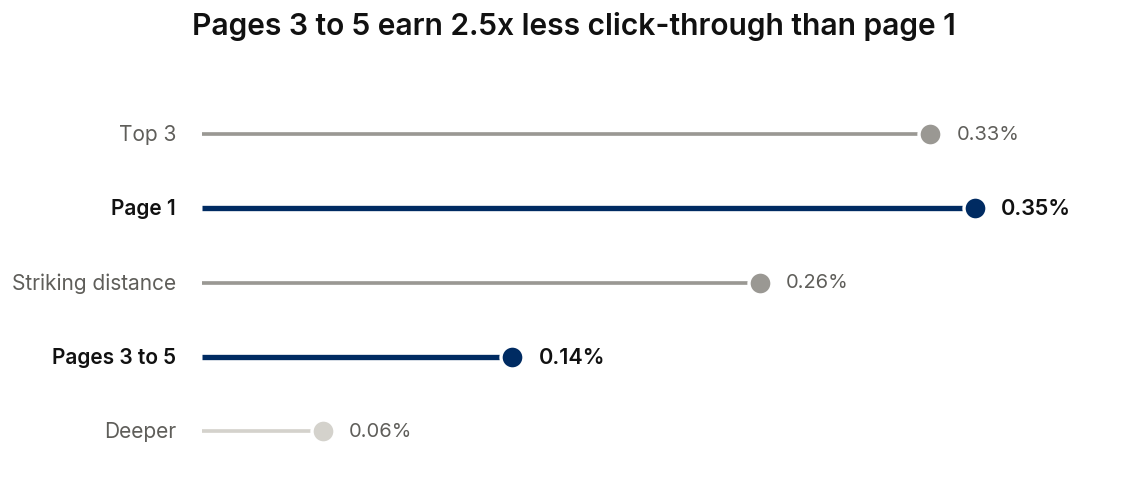

In [8]:
# Chart: mean CTR for each position tier, with the two tiers the finding compares in navy.
COLOR = {"top_3": GRAY, "page_1": NAVY, "striking": GRAY, "page_3_5": NAVY, "deep": PALE}
LABEL = {"top_3": "Top 3", "page_1": "Page 1", "striking": "Striking distance", "page_3_5": "Pages 3 to 5", "deep": "Deeper"}
ratio = by_tier.loc["page_1", "mean_ctr"] / by_tier.loc["page_3_5", "mean_ctr"]

fig, ax = plt.subplots(figsize=(10, 4.6), dpi=120, facecolor=SURFACE)
fig.subplots_adjust(left=0.19, right=0.95, top=0.80, bottom=0.10)
ax.set_facecolor(SURFACE)
for y, tier in enumerate(reversed(TIERS)):
    value = by_tier.loc[tier, "mean_ctr"]
    story = COLOR[tier] == NAVY
    ax.hlines(y, 0, value, color=COLOR[tier], linewidth=3.2 if story else 2.2, zorder=2)
    ax.scatter(value, y, s=190, color=COLOR[tier], edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.text(value + 0.012, y, f"{value:.2f}%", va="center", ha="left", color=INK if story else MUTED,
            fontsize=13 if story else 12, fontweight="semibold" if story else "regular")
    ax.text(-0.012, y, LABEL[tier], va="center", ha="right", color=INK if story else MUTED,
            fontsize=12.5, fontweight="semibold" if story else "regular")
ax.set_xlim(0, by_tier["mean_ctr"].max() * 1.18)
ax.set_ylim(-0.6, len(TIERS) - 0.4)
ax.set_yticks([])
ax.set_xticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(0.5, 0.90, f"Pages 3 to 5 earn {ratio:.1f}x less click-through than page 1", ha="center", color=INK,
         fontsize=18, fontweight="semibold")
plt.show()

**Finding:** click-through falls away once a page is below page 1.

- **The mean.** Page CTR goes from 0.355% on page 1 to 0.256% in striking distance, 0.142% on pages 3 to 5 and 0.055% deeper. A page on pages 3 to 5 earns about 2.5x less than a page 1 page, and a deeper page about 6.5x less.
- **The median agrees.** It runs 0.230%, 0.150%, 0.060% and 0.000% over the same four tiers, so more than half of the deepest pages with 100 or more impressions received no click at all.
- **The pooled rate is flatter at first.** It is level between page 1 and striking distance (0.350% and 0.347%) and then falls (0.155% and 0.039%).

The top-3 tier is the untidy part. It does not beat page 1 on the page averages (0.334% against 0.355% mean, 0.190% against 0.230% median) but it does on the pooled rate (0.487% against 0.350%). Only 533 of its 2,321 pages have 100 or more impressions, so the tier is a few well-seen pages plus many barely seen ones, and the measure you pick decides who wins. Treat the order of the top two tiers as unsettled and the fall below page 1 as the solid result.

### Discovery C — is longer content the lever?

Compare word count for **declining** vs **growing** pages.

**Method:** this cell groups every page by its trend direction and shows the median word count of each group, with the number of pages behind it. The median is used because a few very long articles would drag a mean upward.

In [9]:
words = df.groupby("trend_direction")["word_count"].agg(pages="size", median="median").sort_values("median", ascending=False)
show_table("Median word count by trend direction", pd.DataFrame({
    "Pages": words["pages"].map("{:,}".format),
    "Median word count": words["median"].map("{:,.0f}".format),
}, index=words.index.rename("Trend direction")))

**Median word count by trend direction**

| Trend direction | Pages | Median word count |
| --- | ---: | ---: |
| stable | 5,962 | 2,912 |
| down | 16,262 | 2,909 |
| up | 4,388 | 2,848 |
| flat | 1,152 | 2,698 |
| new | 2,236 | 2,239 |

**Finding:** length is not the lever.

- **Declining against growing.** The median declining page has 2,909 words and the median growing page 2,848, a gap of 61 words, about 2%. Stable pages sit at 2,912.
- **The one outlier.** `new` pages are shorter at 2,239 words, but they have no history to decline from, so that is not evidence that short pages decline.

This is observed only. It shows that word count does not separate declining pages from growing ones in this sample, and it does not show that rewriting a page would not help.

## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR _at the same position tier_?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as _observed / directional_ — never "I proved Google's algorithm." Keep client data out of anything you publish.

**My choice: the second bullet.** The first bullet turns out to be a non-test here, because every page in this dataset has impressions above zero, so Discovery A already used exactly those pages. The second bullet needs care for a different reason: it compares groups, and a group can look bad simply because of who owns it. So the cell below counts the clients behind every group before it ranks anything.

### My discovery: which content type clicks worst, at the same position tier?

**Method, step by step:**

1. **Groups pages** by position tier and content type, and adds up their impressions and clicks to get each group's pooled CTR.
2. **Counts the pages and the clients** in each group. A group needs at least 30 pages and 1,000 impressions to count as having enough data, because a rate built on a handful of pages says little.
3. **Runs the luck test** against the `keyword article` rate in the same tier: if a group clicked at that rate, how often would it get this few clicks by chance? The test treats clicks as Poisson counts, which understates how much real clicks vary, so read the probabilities as directional.
4. **Picks the lowest pooled CTR** in each tier among the groups with enough data.

In [10]:
from scipy.stats import poisson

MIN_PAGES, MIN_IMPRESSIONS = 30, 1_000
REFERENCE = "keyword article"

groups = df.groupby(["position_tier", "content_type"]).agg(
    pages=("content_id", "size"), clients=("client_id", "nunique"),
    impressions=("impressions_90d", "sum"), clicks=("clicks_90d", "sum"),
).reset_index()
groups["pooled_ctr"] = 100 * groups["clicks"] / groups["impressions"]
groups["enough_data"] = (groups["pages"] >= MIN_PAGES) & (groups["impressions"] >= MIN_IMPRESSIONS)

# The luck test asks how often the reference content type's rate would produce this few clicks.
reference_rate = groups[groups["content_type"] == REFERENCE].set_index("position_tier")["pooled_ctr"] / 100
groups["expected_clicks"] = groups["impressions"] * groups["position_tier"].map(reference_rate)
groups["p_luck"] = poisson.cdf(groups["clicks"], groups["expected_clicks"])
groups["tier_order"] = groups["position_tier"].map(TIERS.index)
groups = groups.sort_values(["tier_order", "pooled_ctr"]).reset_index(drop=True)

is_reference = groups["content_type"] == REFERENCE
show_table("Click-through by position tier and content type", pd.DataFrame({
    "Position tier": groups["position_tier"],
    "Content type": groups["content_type"],
    "Pages": groups["pages"].map("{:,}".format),
    "Clients": groups["clients"],
    "Impressions": groups["impressions"].map("{:,}".format),
    "Clicks": groups["clicks"].map("{:,}".format),
    "Pooled CTR": groups["pooled_ctr"].map("{:.3f}%".format),
    "Enough data": groups["enough_data"].map({True: "yes", False: "no"}),
    "Chance of luck": np.where(is_reference, "reference", groups["p_luck"].map("{:.4f}".format)),
}))

worst = groups[groups["enough_data"]].groupby("position_tier").head(1).sort_values("tier_order")
show_table("Lowest pooled CTR in each tier, among groups with enough data", pd.DataFrame({
    "Position tier": worst["position_tier"],
    "Content type": worst["content_type"],
    "Pooled CTR": worst["pooled_ctr"].map("{:.3f}%".format),
    "Keyword-article CTR": worst["position_tier"].map(reference_rate).map(lambda r: f"{100 * r:.3f}%"),
    "Pages": worst["pages"].map("{:,}".format),
    "Clients": worst["clients"],
}))

**Click-through by position tier and content type**

| Position tier | Content type | Pages | Clients | Impressions | Clicks | Pooled CTR | Enough data | Chance of luck |
| --- | --- | ---: | ---: | ---: | ---: | ---: | --- | --- |
| top_3 | comparison article | 3 | 1 | 275 | 0 | 0.000% | no | 0.2637 |
| top_3 | keyword article | 1,395 | 26 | 7,020,217 | 34,032 | 0.485% | yes | reference |
| top_3 | feedly article | 923 | 6 | 12,468 | 323 | 2.591% | yes | 1.0000 |
| page_1 | comparison article | 435 | 1 | 128,494 | 106 | 0.082% | yes | 0.0000 |
| page_1 | keyword article | 10,501 | 30 | 89,187,244 | 312,119 | 0.350% | yes | reference |
| page_1 | feedly article | 878 | 6 | 259,699 | 1,579 | 0.608% | yes | 1.0000 |
| striking | comparison article | 180 | 1 | 30,472 | 49 | 0.161% | yes | 0.0000 |
| striking | feedly article | 181 | 6 | 87,997 | 253 | 0.288% | yes | 0.0011 |
| striking | keyword article | 6,943 | 31 | 22,873,585 | 79,452 | 0.347% | yes | reference |
| page_3_5 | comparison article | 79 | 1 | 24,438 | 23 | 0.094% | yes | 0.0066 |
| page_3_5 | keyword article | 7,064 | 28 | 35,131,126 | 54,388 | 0.155% | yes | reference |
| page_3_5 | feedly article | 99 | 5 | 26,697 | 88 | 0.330% | yes | 1.0000 |
| deep | keyword article | 1,304 | 22 | 1,219,768 | 502 | 0.041% | yes | reference |
| deep | feedly article | 15 | 5 | 8,509 | 6 | 0.071% | no | 0.9346 |

**Lowest pooled CTR in each tier, among groups with enough data**

| Position tier | Content type | Pooled CTR | Keyword-article CTR | Pages | Clients |
| --- | --- | ---: | ---: | ---: | ---: |
| top_3 | keyword article | 0.485% | 0.485% | 1,395 | 26 |
| page_1 | comparison article | 0.082% | 0.350% | 435 | 1 |
| striking | comparison article | 0.161% | 0.347% | 180 | 1 |
| page_3_5 | comparison article | 0.094% | 0.155% | 79 | 1 |
| deep | keyword article | 0.041% | 0.041% | 1,304 | 22 |

**Finding:** comparison articles click least wherever they have enough data, and by a wide margin.

- **Page 1.** They earn 0.082% against 0.350% for keyword articles, about 4.3x less. Luck would produce a gap this size less than 1 time in 10,000.
- **Striking distance.** 0.161% against 0.347%, about 2.2x less, again less than 1 time in 10,000 by luck.
- **Pages 3 to 5.** 0.094% against 0.155%, about 1.6x less, with luck explaining it about 7 times in 1,000.
- **Feedly articles** sit above the keyword rate at page 1 (0.608%) and in the top 3 (2.591%), though the top-3 figure rests on only 12,468 impressions.

Two rows need care. In the top-3 tier, keyword articles come out lowest only because the comparison group has just 3 pages and so does not count, and in the deep tier they are the only group with enough data. Neither row says anything about content type. The **Clients** column is the real warning: every comparison article belongs to a single client, and the luck test cannot tell a content-type effect from a client effect.

**Method:** because one client owns every comparison article, the table above cannot separate "comparison articles click worse" from "this client's pages click worse". This cell removes the client from the comparison where it can: for each tier it keeps only clients that have **both** content types with at least 1,000 impressions each, and compares the two rates **within the same client**.

In [11]:
rows = []
for tier in TIERS:
    mine = df[df["position_tier"] == tier]
    per_client = mine.groupby(["client_id", "content_type"]).agg(impressions=("impressions_90d", "sum"), clicks=("clicks_90d", "sum"))
    per_client = per_client[per_client["impressions"] >= MIN_IMPRESSIONS].reset_index()
    comp = per_client[per_client["content_type"] == "comparison article"].set_index("client_id")
    keyw = per_client[per_client["content_type"] == "keyword article"].set_index("client_id")
    shared = comp.index.intersection(keyw.index)
    if len(shared):
        comp_ctr = 100 * comp.loc[shared, "clicks"].sum() / comp.loc[shared, "impressions"].sum()
        keyw_ctr = 100 * keyw.loc[shared, "clicks"].sum() / keyw.loc[shared, "impressions"].sum()
        rows.append({"Position tier": tier, "Clients with both": len(shared), "Comparison CTR": f"{comp_ctr:.3f}%",
                     "Keyword CTR (same client)": f"{keyw_ctr:.3f}%", "Ratio": f"{comp_ctr / keyw_ctr:.2f}x"})
    else:
        rows.append({"Position tier": tier, "Clients with both": 0, "Comparison CTR": "n/a",
                     "Keyword CTR (same client)": "n/a", "Ratio": "n/a"})
show_table("Comparison against keyword articles inside the same client", pd.DataFrame(rows))

**Comparison against keyword articles inside the same client**

| Position tier | Clients with both | Comparison CTR | Keyword CTR (same client) | Ratio |
| --- | ---: | --- | --- | --- |
| top_3 | 0 | n/a | n/a | n/a |
| page_1 | 1 | 0.082% | 0.171% | 0.48x |
| striking | 1 | 0.161% | 0.157% | 1.03x |
| page_3_5 | 1 | 0.094% | 0.147% | 0.64x |
| deep | 0 | n/a | n/a | n/a |

**Finding:** holding the client fixed roughly halves the gap at page 1, and it disappears in striking distance.

- **Page 1.** Inside the one client that has both types, comparison articles click at 0.082% against 0.171% for that client's own keyword articles (0.48x). The gap shrinks from 4.3x across all clients to about 2.1x within one.
- **Pages 3 to 5.** 0.094% against 0.147% (0.64x).
- **Striking distance.** 0.161% against 0.157% (1.03x), so the two types are level there.

That client's keyword articles click at 0.171% on page 1, against 0.350% for all clients together, which shows that a low CTR is simply typical of this client. Part of the first table's gap was the client and not the content type.

What can be said stays directional: with one client behind every comparison article, the data cannot show that the content type, rather than that client's site, is what clicks less, and the flat striking-distance result shows the gap is not constant. The check that would settle it is comparison articles from a second client.

## Limitations

- **Observed, not causal.** Nothing here shows that changing a page's type changes its clicks; the tables describe how pages in this sample behaved.
- **One sample, one moment.** The dataset is a 30,000-page anonymized slice, and the 90-day window is a single snapshot.
- **Groups can hide their owner.** A content type that belongs to one client cannot be told apart from that client's habits, as the client counts above show.
- **Keep client data out.** Pages here are identified only by anonymous IDs, and nothing in this notebook should be published with more detail than that.

### Save your work

**Colab:** _File → Save a copy in GitHub_ (writes to your own repo — that's your submission) and _File → Save a copy in Drive_ (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.